In [61]:
import os

# --- 0. RESOURCE LIMITATION (Requested: 16 Threads) ---
# Limits the number of threads used by Numpy/Scipy/FakeSpectra to 16
# This prevents the code from hijacking the entire node.
num_cores = 20
os.environ["OMP_NUM_THREADS"] = "20"
os.environ["NUMEXPR_MAX_THREADS"] = "20"
os.environ["MKL_NUM_THREADS"] = "20"
os.environ["VECLIB_MAXIMUM_THREADS"] = "20"

import numpy as np
import h5py
import sys
import pickle
from tqdm import tqdm
import fake_spectra.spectra as spectra
import matplotlib.pyplot as plt

# --- 0. NEW CONFIGURATION ---
def matplotlib_default_config():
    font = {
        'family' : 'serif',
        'weight' : 'normal',
        'size'   : 14
    }
    rcnew = {
        "mathtext.fontset" : "cm", 
        "text.usetex": False,
        'figure.frameon': True,
        'axes.linewidth': 2.,
        "axes.titlesize" : 24,
        "axes.labelsize" : 24,
        "legend.fontsize" : 20,
        'legend.fancybox': True,
        'lines.linewidth': 2.5,
        'xtick.alignment': 'center',
        'xtick.bottom': True,
        'xtick.color': 'black',
        'xtick.direction': 'in',
        'xtick.labelbottom': True,
        'xtick.labelsize': 20,
        'xtick.major.bottom': True,
        'xtick.major.pad': 6.0,
        'xtick.major.size': 10.0,
        'xtick.major.width': 1.5,
        'xtick.minor.bottom': True,
        'xtick.minor.pad': 3.4,
        'xtick.minor.size': 5.0,
        'xtick.minor.visible': True,
        'xtick.minor.width': 1.0,
        'xtick.top': True,
        'ytick.alignment': 'center_baseline',
        'ytick.color': 'black',
        'ytick.direction': 'in',
        'ytick.labelleft': True,
        'ytick.labelsize': 20,
        'ytick.left': True,
        'ytick.major.left': True,
        'ytick.major.pad': 6.0,
        'ytick.major.size': 10.0,
        'ytick.major.width': 1.5,
        'ytick.minor.left': True,
        'ytick.minor.pad': 3.4,
        'ytick.minor.right': True,
        'ytick.minor.size': 5.0,
        'ytick.minor.visible': True,
        'ytick.minor.width': 1.0,
        'ytick.right': True
    }
    return font, rcnew

# Apply Config
%matplotlib widget 
font, rcnew = matplotlib_default_config()
plt.rc('font', **font)
plt.rcParams.update(rcnew)

In [62]:

# ================= CONFIGURATION =================
# We try to load the generic file which we know exists
INPUT_PKL = "TNG_Resolution_Comparison_12_13.pkl"
LAMBDA_LYALPHA = 1215.67  # Angstroms
LIGHT_SPEED = 299792.458  # km/s

# --- CONTROL KNOBS ---
# ADJUSTED TO MATCH YOUR EXISTING FILE (10^10 - 10^11)
MASS_MIN = 10**12.4
MASS_MAX = 10**12.5

# How many specific halos do you want to track per simulation?
N_HALOS_PER_SIM = 2

# Plot styling
SIM_CONFIG = {
    "TNG50-4": {"color": "#1f77b4", "label": "TNG50-4", "linestyle": "-"}, 
    "TNG50-3": {"color": "#ff7f0e", "label": "TNG50-3", "linestyle": "-"}, 
    "TNG50-2": {"color": "#2ca02c", "label": "TNG50-2", "linestyle": "-"}  
}

# --- MATPLOTLIB STYLE ---
def apply_plot_style():
    plt.style.use('default')
    plt.rc('font', family='serif', size=14)
    plt.rcParams['xtick.direction'] = 'in'
    plt.rcParams['ytick.direction'] = 'in'
    plt.rcParams['axes.linewidth'] = 1.5

In [63]:
with open(INPUT_PKL, 'rb') as f:
    master_data = pickle.load(f)

apply_plot_style()

In [66]:
# ================= DIAGNOSTIC STEP =================
# Check what mass range is ACTUALLY in the file
all_masses = []
for sim in SIM_CONFIG:
    if sim in master_data:
        for h in master_data[sim]:
            all_masses.append(h['mass'])

if len(all_masses) > 0:
    min_in_file = np.min(all_masses)
    max_in_file = np.max(all_masses)
    print(f"📊 DIAGNOSTIC: File contains masses from 10^{np.log10(min_in_file):.2f} to 10^{np.log10(max_in_file):.2f} M_sun")
    
    # Auto-adjust if the requested range is totally outside
    if MASS_MIN > max_in_file or MASS_MAX < min_in_file:
        print(f"⚠️  WARNING: Requested range (10^{np.log10(MASS_MIN):.1f}-10^{np.log10(MASS_MAX):.1f}) is outside file range!")
        print(f"⚙️  Auto-correcting to use available data...")
        MASS_MIN = min_in_file
        MASS_MAX = max_in_file

📊 DIAGNOSTIC: File contains masses from 10^11.70 to 10^12.96 M_sun


🎲 Selecting specific halos to track...
   ✅ TNG50-4: Tracking 2 halo(s) (Masses: ['2.63e+12', '3.02e+12'])
   ✅ TNG50-3: Tracking 2 halo(s) (Masses: ['2.54e+12', '2.72e+12'])
   ✅ TNG50-2: Tracking 2 halo(s) (Masses: ['2.63e+12', '3.15e+12'])

🎨 Generating plots...


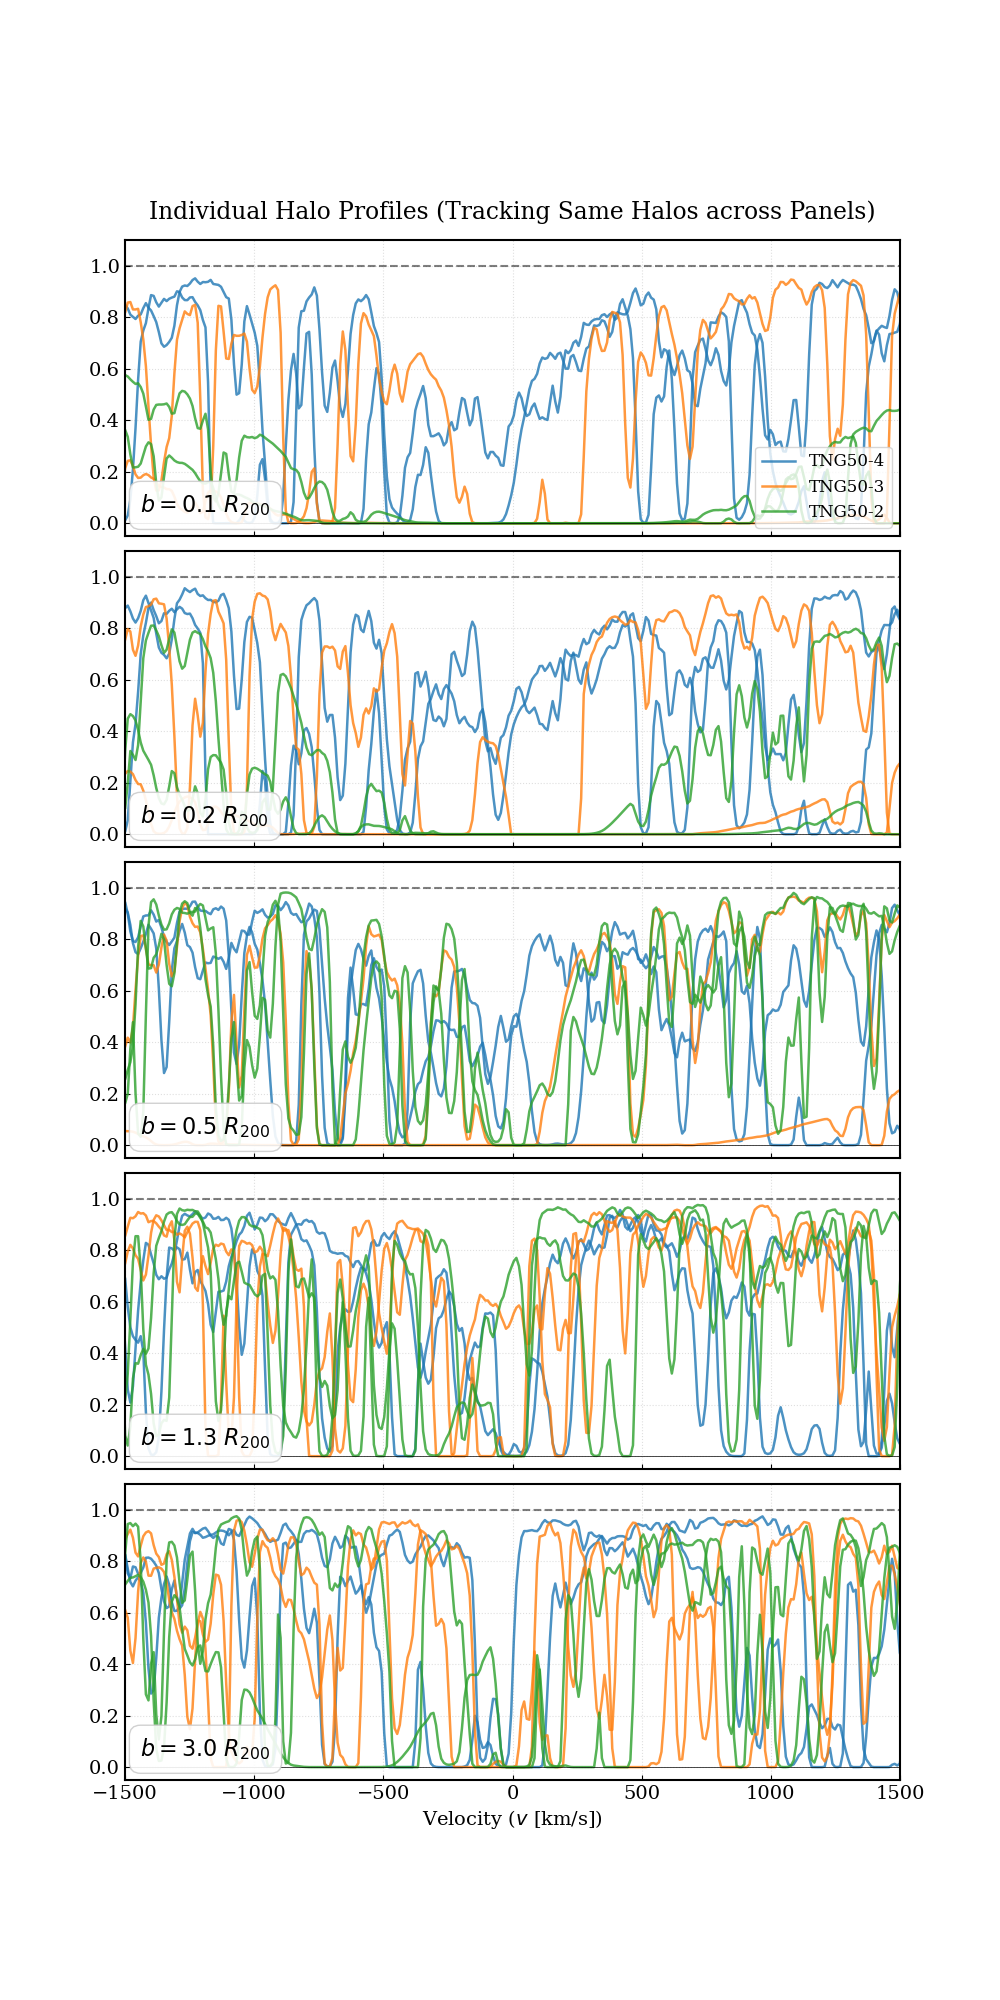

In [67]:
# ================= SELECTION LOGIC =================
print("🎲 Selecting specific halos to track...")

tracked_halos = {} 
np.random.seed(58) 

for sim_name in SIM_CONFIG.keys():
    if sim_name not in master_data: continue
    
    all_halos = master_data[sim_name]
    
    # 1. Filter candidates by Mass
    candidates = [
        h for h in all_halos 
        if (h['mass'] >= MASS_MIN) and (h['mass'] <= MASS_MAX)
    ]
    
    if len(candidates) > 0:
        # 2. Select N distinct halos to track
        n_to_pick = min(len(candidates), N_HALOS_PER_SIM)
        chosen_halos = np.random.choice(candidates, n_to_pick, replace=False)
        tracked_halos[sim_name] = chosen_halos
        
        # Safe print using external formatting
        mass_str = [f"{h['mass']:.2e}" for h in chosen_halos]
        print(f"   ✅ {sim_name}: Tracking {len(chosen_halos)} halo(s) (Masses: {mass_str})")
    else:
        print(f"   ❌ {sim_name}: No halos found in range.")
        tracked_halos[sim_name] = []

# ================= PLOTTING LOGIC =================
if not any(len(h) > 0 for h in tracked_halos.values()):
    print("\n⚠️  NO HALOS SELECTED. PLOT CANCELED.")
else:
    num_radii = 5 
    fig, axes = plt.subplots(nrows=num_radii, ncols=1, figsize=(10, 20), sharex=True)
    plt.subplots_adjust(hspace=0.05)

    print("\n🎨 Generating plots...")

    for i, ax in enumerate(axes):
        current_r_mult = None
        
        for sim_name, style in SIM_CONFIG.items():
            if sim_name not in tracked_halos: continue
            
            my_halos = tracked_halos[sim_name]
            first_label = True
            
            # Establish velocity axis
            if len(my_halos) > 0 and i < len(my_halos[0]['radii_data']):
                 sample_wave = my_halos[0]['radii_data'][i]['wave']
                 vel_axis = LIGHT_SPEED * (sample_wave / LAMBDA_LYALPHA - 1)
            
            for halo in my_halos:
                if i < len(halo['radii_data']):
                    r_data = halo['radii_data'][i]
                    current_r_mult = r_data['r_mult']
                    flux_matrix = r_data['flux_matrix'] 
                    
                    # --- THE "RANDOM SKEWER" STEP ---
                    # Choose 1 random skewer (0-11) freshly for THIS panel
                    random_skewer_idx = np.random.randint(0, 12)
                    skewer_flux = flux_matrix[random_skewer_idx]
                    
                    label = style['label'] if (first_label and i == 0) else None
                    first_label = False
                    
                    ax.plot(vel_axis, skewer_flux, 
                            color=style['color'], 
                            linestyle=style['linestyle'],
                            linewidth=1.8, alpha=0.8, label=label)

        if current_r_mult is not None:
            ax.text(0.02, 0.08, f"$b = {current_r_mult:.1f} \ R_{{200}}$", transform=ax.transAxes,
                    fontsize=16, fontweight='bold', 
                    bbox=dict(facecolor='white', alpha=0.9, edgecolor='#cccccc', boxstyle='round,pad=0.5'))
        
        ax.set_ylim(-0.05, 1.1) 
        ax.grid(True, linestyle=':', alpha=0.4)
        ax.axhline(1, color='k', ls='--', alpha=0.5)
        ax.axhline(0, color='k', ls='-', lw=0.5)

    axes[-1].set_xlabel(r"Velocity ($v$ [km/s])")
    axes[-1].set_xlim(-1500, 1500) 
    
    axes[0].set_title(rf"Individual Halo Profiles (Tracking Same Halos across Panels)", pad=15)
    axes[0].legend(loc="lower right", frameon=True, fontsize=12)
    
    plt.show()